# 4. Evaluation & Comparison (system 4)

This notebook compares every model trained in notebooks 3A-3D across the four tasks:

| Task | Notebook | Inputs | Predicts |
|---|---|---|---|
| Estimation, endogenous | 3A | irradiance, module temperature | power at the same minute |
| Estimation, exogenous | 3B | ambient temperature, calendar | power at the same minute |
| Forecast 1 h | 3C | lags of power / irradiance, temperature, calendar | power of a 15-min slot 1 h ahead |
| Forecast 3 h | 3D | same as 3C | power of a 15-min slot 3 h ahead |

It reads the saved metrics, predictions and models; only section 4.3 trains two quick models again, on purpose, to show what a random train/test split would report. Sections: 4.0 load, 4.1 metrics, 4.2 ties, 4.3 random vs chronological split, 4.4 efficiency, 4.5 predicted vs actual, 4.6 residuals, 4.7 feature importance, 4.8 best model per task.

## Setup

In [1]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "data" / "features").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the thesis project root.")

SYSTEM_ID = 4
TARGET = "dc_power__314"
TASKS = {
    "endogenous": "Estimation, endogenous",
    "exogenous": "Estimation, exogenous",
    "forecast_1h": "Forecast 1 h",
    "forecast_3h": "Forecast 3 h",
}
FORECAST_HOURS = {"forecast_1h": 1, "forecast_3h": 3}
MODELS = ["Linear Regression", "Decision Tree", "Random Forest", "MLP", "XGBoost"]
MODEL_SLUGS = {"Linear Regression": "linear_regression", "Decision Tree": "decision_tree",
               "Random Forest": "random_forest", "MLP": "mlp", "XGBoost": "xgboost"}
MODEL_SHORT = {"Linear Regression": "LR", "Decision Tree": "DT", "Random Forest": "RF",
               "MLP": "MLP", "XGBoost": "XGB"}
TASK_COLORS = {"endogenous": "tab:blue", "exogenous": "tab:orange",
               "forecast_1h": "tab:green", "forecast_3h": "tab:red"}

METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
EXPERIMENTS_DIR = PROJECT_ROOT / "artifacts" / "experiments"
MODELS_DIR = PROJECT_ROOT / "artifacts" / "models"
FEATURES_DIR = PROJECT_ROOT / "data" / "features"
CLEANED_DIR = PROJECT_ROOT / "data" / "cleaned"


def regression_metrics(y_true, y_pred):
    """MAE, RMSE and R² in watts."""
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}


print(f"Project root: {PROJECT_ROOT}")

Project root: /home/raul/Desktop/solar-data-all/thesis


## 4.0 Load the saved results

For every task: the model metrics (3A-3D), the test predictions of every model and baseline, and the configuration summary that points to the exported features.

In [2]:
config_summary = pd.read_csv(METRICS_DIR / f"system_{SYSTEM_ID}_feature_configs.csv", index_col="config")
metrics = {task: pd.read_csv(METRICS_DIR / f"system_{SYSTEM_ID}_{task}_model_metrics.csv", index_col="model")
           for task in TASKS}
predictions = {task: pd.read_csv(EXPERIMENTS_DIR / f"system_{SYSTEM_ID}_{task}_test_predictions.csv",
                                 index_col="datetime", parse_dates=True)
               for task in TASKS}


def load_features(task, part):
    """Load one exported partition of a task (scaled features or targets)."""
    group = config_summary.loc[task, "group_name"]
    return pd.read_csv(FEATURES_DIR / group / f"{part}_{group}.csv", index_col="datetime", parse_dates=True)


display(pd.DataFrame(
    {TASKS[task]: {"test rows": len(pred), "start": pred.index.min(), "end": pred.index.max(),
                   "models / baselines": ", ".join(c for c in pred.columns if c != "y_true")}
     for task, pred in predictions.items()}
).T)

,test rows,start,end,models / baselines
"Estimation, endogenous",264865,2016-01-21 08:47:00,2023-01-31 16:17:00,"Linear Regression, Decision Tree, Random Fores..."
"Estimation, exogenous",264865,2016-01-21 08:47:00,2023-01-31 16:17:00,"Linear Regression, Decision Tree, Random Fores..."
Forecast 1 h,21011,2016-01-21 09:00:00,2023-01-31 16:45:00,"Persistence, Same time yesterday, Linear Regre..."
Forecast 3 h,20884,2016-01-21 09:00:00,2023-01-31 16:45:00,"Persistence, Same time yesterday, Linear Regre..."


## 4.1 Metrics table

### 4.1.1 Clear-sky persistence (stricter forecasting reference)

Plain persistence ("the power stays as it is now") ignores that the sun moves: 3 h after 09:00 the power is naturally much higher. A stricter reference keeps the **clear-sky index** constant instead of the power: `forecast = (P(origin) / P_cs(origin)) × P_cs(target)`, where `P_cs` is a clear-sky power proxy, the 95th percentile of the power for each (week of year, 15-minute slot) over the **training period** only. The index is capped at `MAX_CLEAR_SKY_INDEX`, and set to 1 when `P_cs(origin)` is too small to divide by.

In [3]:
# Clear-sky proxy settings.
CLEAR_SKY_QUANTILE = 0.95
MIN_CLEAR_SKY_POWER_W = 20.0
MAX_CLEAR_SKY_INDEX = 1.2

grid = pd.read_csv(CLEANED_DIR / f"system_{SYSTEM_ID}_cleaned_15min.csv", index_col="datetime", parse_dates=True)
split_time = predictions["endogenous"].index.min()  # first test timestamp of every task


def calendar_key(index):
    """(week of year 1-52, 15-minute slot of day 0-95) for a DatetimeIndex."""
    week = np.minimum(index.isocalendar().week.to_numpy(dtype=int), 52)
    return [week, (index.hour * 4 + index.minute // 15).to_numpy()]


train_power = grid.loc[grid.index < split_time, TARGET].dropna()
clear_sky = train_power.groupby(calendar_key(train_power.index)).quantile(CLEAR_SKY_QUANTILE)


def clear_sky_power(index):
    return clear_sky.reindex(pd.MultiIndex.from_arrays(calendar_key(index))).fillna(0).to_numpy()


for task, hours in FORECAST_HOURS.items():
    pred = predictions[task]
    cs_origin = clear_sky_power(pred.index - pd.Timedelta(hours=hours))
    cs_target = clear_sky_power(pred.index)
    sky_index = np.where(cs_origin > MIN_CLEAR_SKY_POWER_W,
                         pred["Persistence"] / np.maximum(cs_origin, MIN_CLEAR_SKY_POWER_W), 1.0)
    pred["Clear-sky persistence"] = np.clip(sky_index, 0, MAX_CLEAR_SKY_INDEX) * cs_target
    metrics[task].loc["Clear-sky persistence", ["test_MAE", "test_RMSE", "test_R2"]] = list(
        regression_metrics(pred["y_true"], pred["Clear-sky persistence"]).values())
    print(f"{TASKS[task]}: RMSE persistence {metrics[task].loc['Persistence', 'test_RMSE']:.1f} W, "
          f"clear-sky persistence {metrics[task].loc['Clear-sky persistence', 'test_RMSE']:.1f} W, "
          f"same time yesterday {metrics[task].loc['Same time yesterday', 'test_RMSE']:.1f} W")

Forecast 1 h: RMSE persistence 211.8 W, clear-sky persistence 165.2 W, same time yesterday 279.2 W
Forecast 3 h: RMSE persistence 397.5 W, clear-sky persistence 237.0 W, same time yesterday 278.9 W


### 4.1.2 All tasks

One table with every model and baseline: test MAE / RMSE / R², the CV RMSE mean ± std from notebooks 3A-3D, and for the forecasts the skill against plain and clear-sky persistence (`1 − RMSE / RMSE_reference`). nRMSE is the RMSE as a percentage of the mean test power, so tasks with different rows can be compared. Saved to `artifacts/metrics/`.

In [4]:
rows = []
for task in TASKS:
    mean_power = predictions[task]["y_true"].mean()
    for model, row in metrics[task].iterrows():
        entry = {"task": TASKS[task], "model": model,
                 "test_MAE": row["test_MAE"], "test_RMSE": row["test_RMSE"],
                 "nRMSE_%": 100 * row["test_RMSE"] / mean_power, "test_R2": row["test_R2"],
                 "cv_RMSE_mean": row.get("cv_RMSE_mean"), "cv_RMSE_std": row.get("cv_RMSE_std")}
        if task in FORECAST_HOURS:
            entry["skill_vs_persistence"] = 1 - row["test_RMSE"] / metrics[task].loc["Persistence", "test_RMSE"]
            entry["skill_vs_clear_sky"] = 1 - row["test_RMSE"] / metrics[task].loc["Clear-sky persistence", "test_RMSE"]
        rows.append(entry)

summary = pd.DataFrame(rows).set_index(["task", "model"])
SUMMARY_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_eval_metrics_all_tasks.csv"
summary.to_csv(SUMMARY_PATH)
with pd.option_context("display.max_rows", 50):
    display(summary.round(3))
print(f"Saved to: {SUMMARY_PATH}")

test_MAE  test_RMSE  nRMSE_%  \
task                   model                                                 
Estimation, endogenous Linear Regression        22.018     32.025    6.543   
                       Decision Tree            19.168     29.098    5.945   
                       Random Forest            19.034     28.904    5.905   
                       MLP                      18.890     28.290    5.780   
                       XGBoost                  19.094     28.874    5.899   
Estimation, exogenous  Linear Regression       180.959    223.050   45.569   
                       Decision Tree           171.638    232.003   47.398   
                       Random Forest           167.508    222.785   45.514   
                       MLP                     166.496    217.159   44.365   
                       XGBoost                 166.968    222.247   45.405   
Forecast 1 h           Persistence             154.273    211.768   52.239   
                       Same time yesterday     173.473    279.185   68.870   
                       Linear Regression       116.745    159.841   39.430   
                       Decision Tree            91.155    145.960   36.006   
                       Random Forest            87.634    140.033   34.544   
                       MLP                      89.366    141.553   34.919   
                       XGBoost                  88.087    140.864   34.749   
                       Clear-sky persistence    94.028    165.209   40.754   
Forecast 3 h           Persistence             314.547    397.458   98.124   
                       Same time yesterday     173.330    278.944   68.866   
                       Linear Regression       161.610    204.472   50.480   
                       Decision Tree           130.279    187.546   46.301   
                       Random Forest           128.189    180.401   44.537   
                       MLP                     129.691    179.920   44.419   
                       XGBoost                 128.255    182.035   44.941   
                       Clear-sky persistence   146.999    236.953   58.499   

                                              test_R2  cv_RMSE_mean  \
task                   model                                          
Estimation, endogenous Linear Regression        0.989        28.100   
                       Decision Tree            0.991        24.950   
                       Random Forest            0.991        24.464   
                       MLP                      0.991        24.362   
                       XGBoost                  0.991        24.954   
Estimation, exogenous  Linear Regression        0.450       225.733   
                       Decision Tree            0.405       232.669   
                       Random Forest            0.451       222.016   
                       MLP                      0.478       218.001   
                       XGBoost                  0.454       231.231   
Forecast 1 h           Persistence              0.565           NaN   
                       Same time yesterday      0.244           NaN   
                       Linear Regression        0.752       164.797   
                       Decision Tree            0.793       156.281   
                       Random Forest            0.810       149.248   
                       MLP                      0.806       150.160   
                       XGBoost                  0.808       151.555   
                       Clear-sky persistence    0.735           NaN   
Forecast 3 h           Persistence             -0.533           NaN   
                       Same time yesterday      0.245           NaN   
                       Linear Regression        0.594       209.994   
                       Decision Tree            0.659       201.284   
                       Random Forest            0.684       190.156   
                       MLP                      0.686       189.453   
               

Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_eval_metrics_all_tasks.csv


## 4.2 Ties between models

Two models whose test RMSE differs by a watt may simply be equally good. A **paired block bootstrap** checks this: test days are resampled with replacement (whole days, because neighbouring minutes are correlated), and for every resample the RMSE of each model is recomputed on the same rows. A model is **tied** with the best one when the 95% interval of its RMSE difference includes 0.

In [5]:
# Bootstrap settings.
N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 42

rng = np.random.default_rng(BOOTSTRAP_SEED)
tie_rows = []
for task in TASKS:
    pred = predictions[task]
    squared = pred[MODELS].sub(pred["y_true"], axis=0).pow(2)
    day = pred.index.normalize()
    daily_sse, daily_n = squared.groupby(day).sum().to_numpy(), squared.groupby(day).size().to_numpy()
    draws = rng.integers(0, len(daily_n), size=(N_BOOTSTRAP, len(daily_n)))
    boot_rmse = np.sqrt(daily_sse[draws].sum(axis=1) / daily_n[draws].sum(axis=1)[:, None])

    best = metrics[task].loc[MODELS, "test_RMSE"].idxmin()
    best_column = MODELS.index(best)
    for column, model in enumerate(MODELS):
        difference = boot_rmse[:, column] - boot_rmse[:, best_column]
        low, high = np.percentile(difference, [2.5, 97.5])
        tie_rows.append({"task": TASKS[task], "model": model,
                         "test_RMSE": metrics[task].loc[model, "test_RMSE"],
                         "diff_vs_best": metrics[task].loc[model, "test_RMSE"] - metrics[task].loc[best, "test_RMSE"],
                         "ci_low": low, "ci_high": high,
                         "tied_with_best": model == best or low <= 0})
    print(f"{TASKS[task]}: {len(daily_n)} test days, best = {best}")

ties = pd.DataFrame(tie_rows).set_index(["task", "model"])
display(ties.round(2))

Estimation, endogenous: 477 test days, best = MLP
Estimation, exogenous: 477 test days, best = MLP
Forecast 1 h: 833 test days, best = Random Forest
Forecast 3 h: 833 test days, best = MLP


test_RMSE  diff_vs_best  ci_low  \
task                   model                                                
Estimation, endogenous Linear Regression      32.03          3.73    3.24   
                       Decision Tree          29.10          0.81    0.24   
                       Random Forest          28.90          0.61    0.09   
                       MLP                    28.29          0.00    0.00   
                       XGBoost                28.87          0.58    0.18   
Estimation, exogenous  Linear Regression     223.05          5.89    1.17   
                       Decision Tree         232.00         14.84   10.78   
                       Random Forest         222.78          5.63    2.33   
                       MLP                   217.16          0.00    0.00   
                       XGBoost               222.25          5.09    1.13   
Forecast 1 h           Linear Regression     159.84         19.81   18.05   
                       Decision Tree         145.96          5.93    5.09   
                       Random Forest         140.03          0.00    0.00   
                       MLP                   141.55          1.52    0.64   
                       XGBoost               140.86          0.83    0.02   
Forecast 3 h           Linear Regression     204.47         24.55   20.46   
                       Decision Tree         187.55          7.63    5.66   
                       Random Forest         180.40          0.48   -1.01   
                       MLP                   179.92          0.00    0.00   
                       XGBoost               182.04          2.11    0.00   

                                          ci_high  tied_with_best  
task                   model                                       
Estimation, endogenous Linear Regression     4.29           False  
                       Decision Tree         1.70           False  
                       Random Forest         1.43           False  
                       MLP                   0.00            True  
                       XGBoost               1.23           False  
Estimation, exogenous  Linear Regression    10.52           False  
                       Decision Tree        19.63           False  
                       Random Forest         9.23           False  
                       MLP                   0.00            True  
                       XGBoost               9.23           False  
Forecast 1 h           Linear Regression    21.62           False  
                       Decision Tree         6.79           False  
                       Random Forest         0.00            True  
                       MLP                   2.36           False  
                       XGBoost               1.71           False  
Forecast 3 h           Linear Regression    28.67           False  
                       Decision Tree         9.48           False  
                       Random Forest         2.08            True  
                       MLP                   0.00            True  
                       XGBoost               4.40           False

## 4.3 Random vs chronological split

The indicative methodology mentions a random train/test split. With minute-level data a random split puts 12:00 in training and 12:01 in test, two almost identical readings, so the test score partly measures memory rather than prediction. Here Linear Regression and Decision Tree (same settings as 3A) are trained again on the same rows with a random 80/20 split and compared with their chronological test RMSE. The gap is the optimism a random split would report. It mixes two effects: neighbouring readings leaking across the split, and a test set drawn from the same years as training.

In [6]:
# Random split settings.
RANDOM_SPLIT_SEED = 42
SPLIT_TASKS = ["endogenous", "exogenous", "forecast_1h"]
split_models = {
    "Linear Regression": lambda: LinearRegression(),
    "Decision Tree": lambda: DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=0),
}

split_rows = []
for task in SPLIT_TASKS:
    X = pd.concat([load_features(task, "X_train"), load_features(task, "X_test")])
    y = pd.concat([load_features(task, "y_train"), load_features(task, "y_test")])[TARGET]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SPLIT_SEED)
    for model, make in split_models.items():
        random_rmse = regression_metrics(y_te, make().fit(X_tr, y_tr).predict(X_te))["RMSE"]
        chrono_rmse = metrics[task].loc[model, "test_RMSE"]
        split_rows.append({"task": TASKS[task], "model": model, "chronological_RMSE": chrono_rmse,
                           "random_RMSE": random_rmse,
                           "random_looks_better_by_%": 100 * (1 - random_rmse / chrono_rmse)})

split_comparison = pd.DataFrame(split_rows).set_index(["task", "model"])
split_comparison.to_csv(METRICS_DIR / f"system_{SYSTEM_ID}_eval_random_vs_chronological.csv")
display(split_comparison.round(2))

chronological_RMSE  random_RMSE  \
task                   model                                                
Estimation, endogenous Linear Regression               32.03        29.15   
                       Decision Tree                   29.10        25.20   
Estimation, exogenous  Linear Regression              223.05       224.29   
                       Decision Tree                  232.00       200.78   
Forecast 1 h           Linear Regression              159.84       161.92   
                       Decision Tree                  145.96       149.29   

                                          random_looks_better_by_%  
task                   model                                        
Estimation, endogenous Linear Regression                      8.97  
                       Decision Tree                         13.39  
Estimation, exogenous  Linear Regression                     -0.55  
                       Decision Tree                         13.46  
Forecast 1 h           Linear Regression                     -1.30  
                       Decision Tree                         -2.28

## 4.4 Efficiency

Accuracy against cost: training time (log scale) against test RMSE, one panel per task because the error levels differ by task. Points are labelled LR, DT, RF, MLP, XGB; the table below adds prediction time and model size.

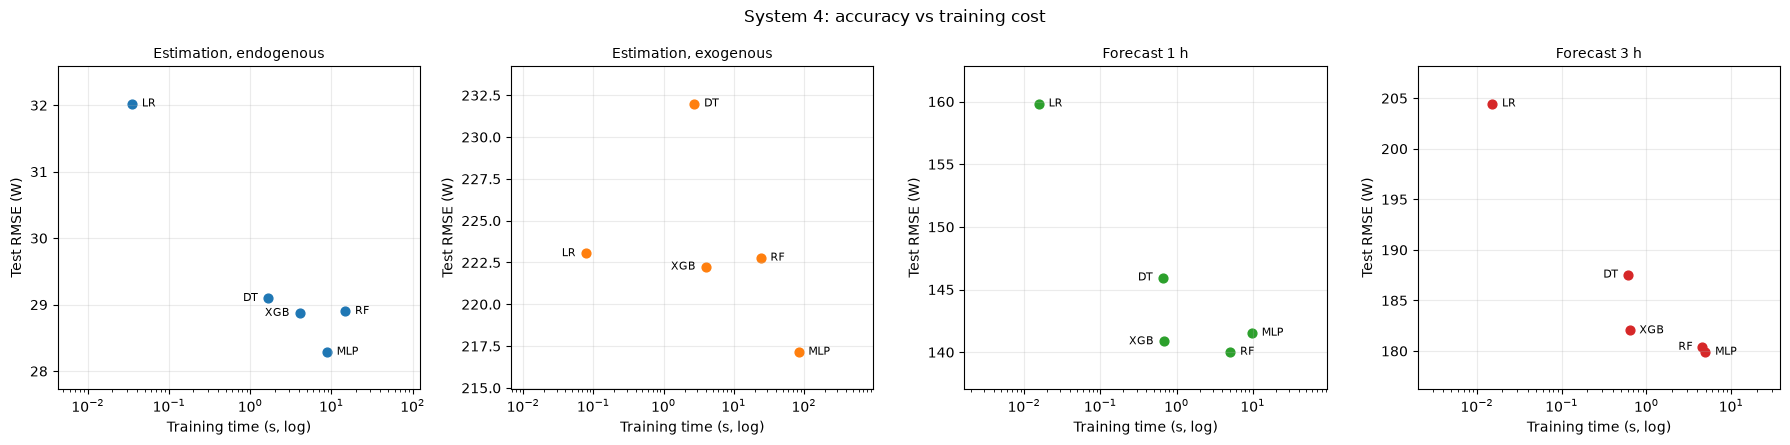

test_RMSE  fit_seconds  \
                       model                                       
Estimation, endogenous Linear Regression     32.025        0.035   
                       Decision Tree         29.098        1.644   
                       Random Forest         28.904       14.797   
                       MLP                   28.290        8.808   
                       XGBoost               28.874        4.052   
Estimation, exogenous  Linear Regression    223.050        0.078   
                       Decision Tree        232.003        2.751   
                       Random Forest        222.785       24.198   
                       MLP                  217.159       84.029   
                       XGBoost              222.247        3.978   
Forecast 1 h           Linear Regression    159.841        0.016   
                       Decision Tree        145.960        0.658   
                       Random Forest        140.033        5.078   
                       MLP                  141.553        9.764   
                       XGBoost              140.864        0.679   
Forecast 3 h           Linear Regression    204.472        0.015   
                       Decision Tree        187.546        0.606   
                       Random Forest        180.401        4.536   
                       MLP                  179.920        4.963   
                       XGBoost              182.035        0.634   

                                          predict_seconds  model_size_kb  
                       model                                              
Estimation, endogenous Linear Regression            0.006          0.617  
                       Decision Tree                0.016        433.657  
                       Random Forest                0.208      40305.796  
                       MLP                          0.073         62.088  
                       XGBoost                      0.183       2252.132  
Estimation, exogenous  Linear Regression            0.006          0.683  
                       Decision Tree                0.007        352.957  
                       Random Forest                0.107      29975.080  
                       MLP                          0.095         68.560  
                       XGBoost                      0.182       2416.165  
Forecast 1 h           Linear Regression            0.001          0.926  
                       Decision Tree                0.002        137.919  
                       Random Forest                0.024      10104.886  
                       MLP                          0.006         81.523  
                       XGBoost                      0.016       2212.478  
Forecast 3 h           Linear Regression            0.001          0.926  
                       Decision Tree                0.002        140.310  
                       Random Forest                0.033      10260.276  
                       MLP                          0.006         79.912  
                       XGBoost                      0.016       2285.503

Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_eval_efficiency.png


In [7]:
EFFICIENCY_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_eval_efficiency.png"
fig, axes = plt.subplots(1, len(TASKS), figsize=(18, 4.5))
for ax, task in zip(axes, TASKS):
    m = metrics[task].loc[MODELS]
    ax.scatter(m["fit_seconds"], m["test_RMSE"], s=40, color=TASK_COLORS[task])
    # Alternate labels right / left in RMSE order so that close points do not overlap.
    for rank, (model, row) in enumerate(m.sort_values("test_RMSE").iterrows()):
        right = rank % 2 == 0
        ax.annotate(MODEL_SHORT[model], (row["fit_seconds"], row["test_RMSE"]),
                    xytext=(7 if right else -7, 0), textcoords="offset points",
                    ha="left" if right else "right", va="center", fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("Training time (s, log)")
    ax.set_ylabel("Test RMSE (W)")
    ax.set_title(TASKS[task], fontsize=10)
    ax.grid(True, alpha=0.25)
    ax.margins(x=0.35, y=0.15)
fig.suptitle(f"System {SYSTEM_ID}: accuracy vs training cost")
fig.tight_layout()
fig.savefig(EFFICIENCY_PLOT_PATH, dpi=160)
plt.show()

efficiency = pd.concat({TASKS[t]: metrics[t].loc[MODELS, ["test_RMSE", "fit_seconds", "predict_seconds",
                                                            "model_size_kb"]] for t in TASKS})
display(efficiency.round(3))
print(f"Saved to: {EFFICIENCY_PLOT_PATH}")

## 4.5 Predicted vs actual

### 4.5.1 Scatter of the best model per task

Each panel shows the best model of a task (lowest test RMSE) as a density plot of predicted against actual power; the diagonal is a perfect prediction.

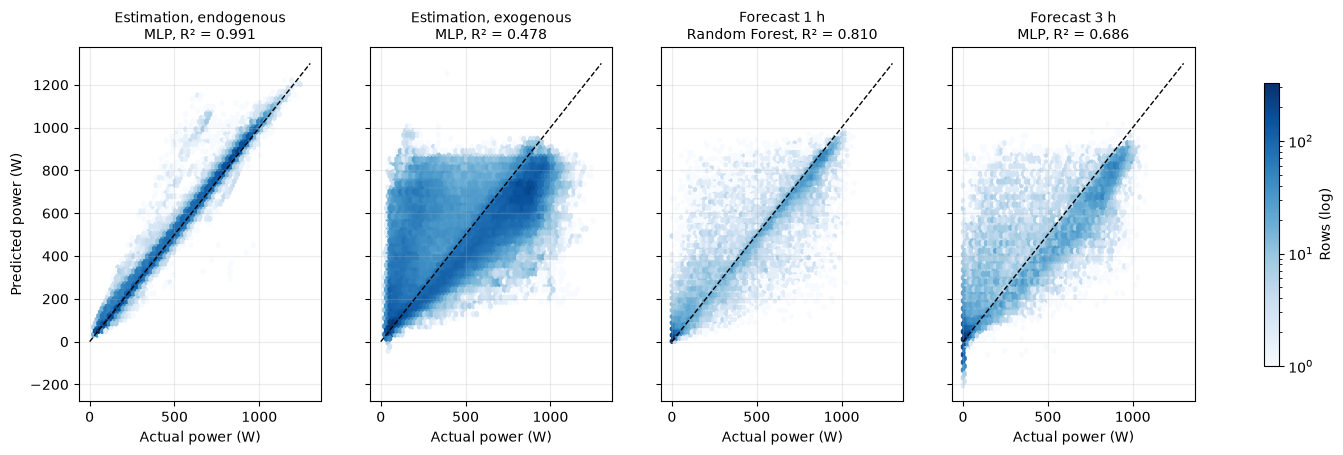

Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_eval_predicted_vs_actual.png


In [8]:
SCATTER_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_eval_predicted_vs_actual.png"
best_models = {task: metrics[task].loc[MODELS, "test_RMSE"].idxmin() for task in TASKS}

fig, axes = plt.subplots(1, len(TASKS), figsize=(18, 4.6), sharex=True, sharey=True)
for ax, task in zip(axes, TASKS):
    pred = predictions[task]
    hexes = ax.hexbin(pred["y_true"], pred[best_models[task]], gridsize=60, bins="log",
                      cmap="Blues", mincnt=1)
    ax.plot([0, 1300], [0, 1300], color="black", linewidth=1, linestyle="--")
    ax.set_title(f"{TASKS[task]}\n{best_models[task]}, R² = {metrics[task].loc[best_models[task], 'test_R2']:.3f}",
                 fontsize=10)
    ax.set_xlabel("Actual power (W)")
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel("Predicted power (W)")
fig.colorbar(hexes, ax=axes, label="Rows (log)", shrink=0.8)
fig.savefig(SCATTER_PLOT_PATH, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved to: {SCATTER_PLOT_PATH}")

### 4.5.2 Sample days

Three test days chosen automatically from the endogenous test data (days with at least `MIN_DAY_ROWS` readings): a **clear** day (high energy, smoothest profile), a **cloudy** day (medium energy, most variable profile) and a **winter** day (December or January, highest energy). Each panel overlays the actual power with the best model of every task; the forecasts are 15-minute slots.

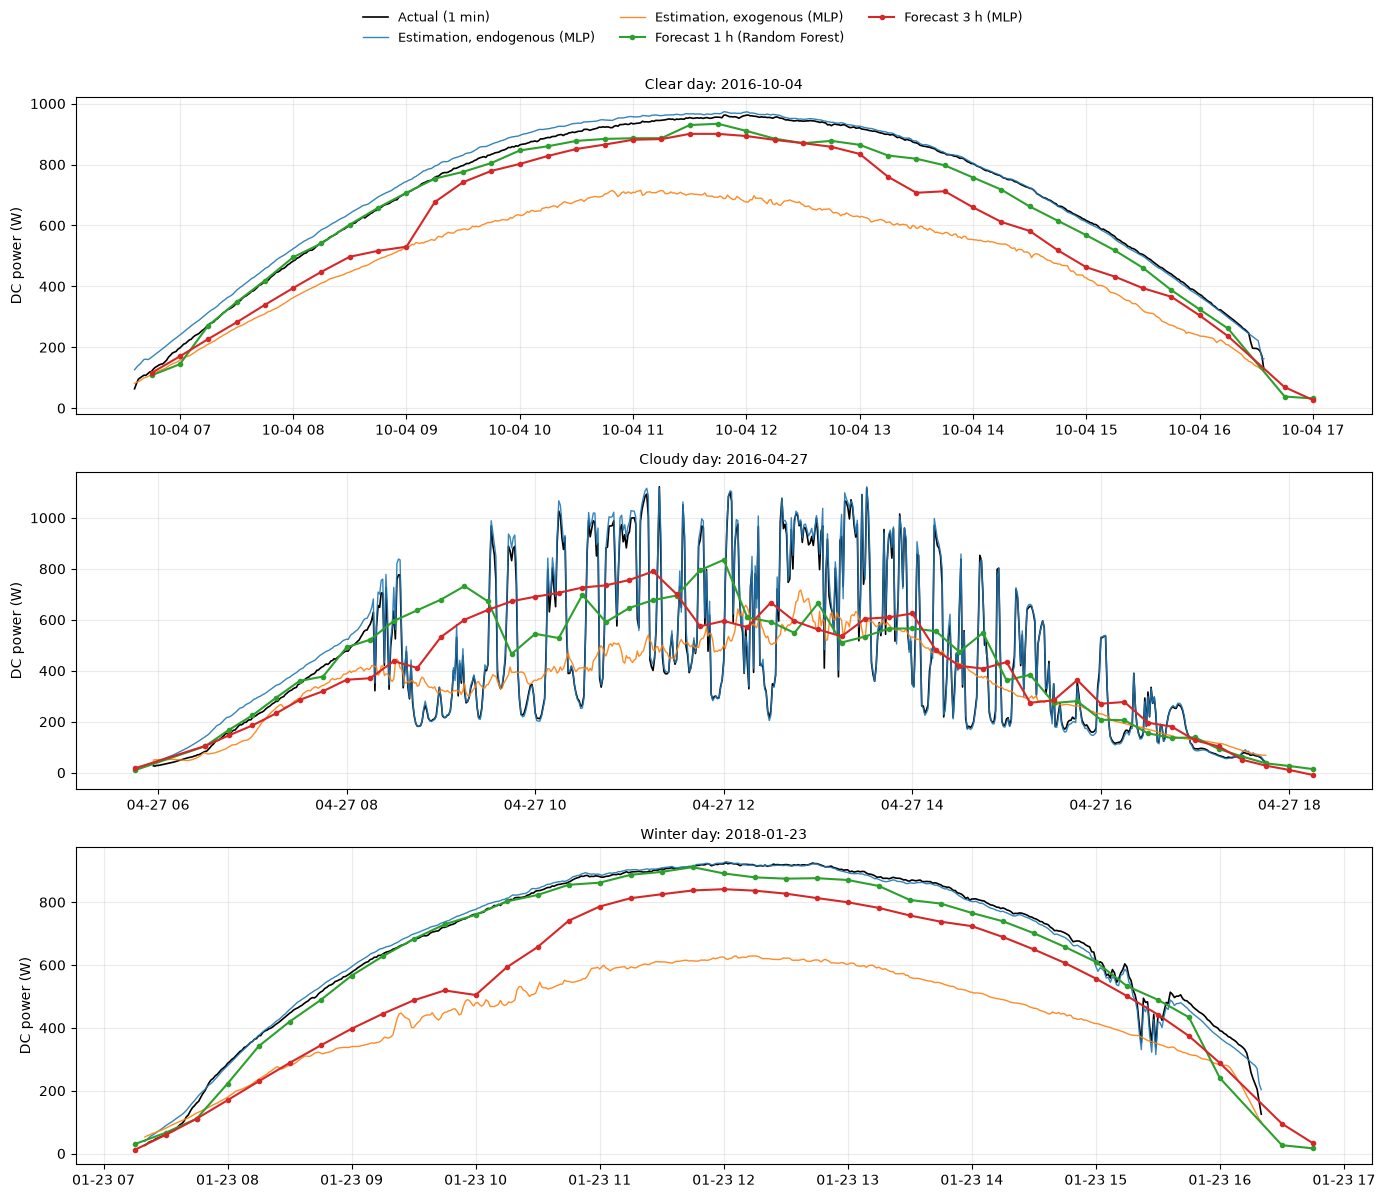

{'Clear day': '2016-10-04', 'Cloudy day': '2016-04-27', 'Winter day': '2018-01-23'}
Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_eval_sample_days.png


In [9]:
# Sample-day selection settings.
MIN_DAY_ROWS = 400

endo = predictions["endogenous"]
day_index = endo.index.normalize()
daily = endo["y_true"].groupby(day_index).agg(["sum", "size"])
daily["roughness"] = (endo["y_true"].diff().abs().groupby(day_index).mean()
                      / endo["y_true"].groupby(day_index).mean())
full_days = daily[daily["size"] >= MIN_DAY_ROWS]
sample_days = {
    "Clear day": full_days[full_days["sum"] >= full_days["sum"].quantile(0.8)]["roughness"].idxmin(),
    "Cloudy day": full_days[full_days["sum"].between(full_days["sum"].quantile(0.4),
                                                     full_days["sum"].quantile(0.8))]["roughness"].idxmax(),
    "Winter day": full_days[full_days.index.month.isin([12, 1])]["sum"].idxmax(),
}

DAYS_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_eval_sample_days.png"
fig, axes = plt.subplots(len(sample_days), 1, figsize=(14, 4 * len(sample_days)))
for ax, (label, day) in zip(axes, sample_days.items()):
    window = slice(day, day + pd.Timedelta(hours=23, minutes=59))
    actual = endo.loc[window, "y_true"]
    ax.plot(actual.index, actual, color="black", linewidth=1.2, label="Actual (1 min)")
    for task in TASKS:
        series = predictions[task].loc[window, best_models[task]]
        style = {"linewidth": 1, "alpha": 0.9} if task in ("endogenous", "exogenous") else \
                {"linewidth": 1.5, "marker": "o", "markersize": 3}
        ax.plot(series.index, series, color=TASK_COLORS[task],
                label=f"{TASKS[task]} ({best_models[task]})", **style)
    ax.set_title(f"{label}: {day.date()}", fontsize=10)
    ax.set_ylabel("DC power (W)")
    ax.grid(True, alpha=0.25)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=9, ncol=3, loc="upper center", frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(DAYS_PLOT_PATH, dpi=160)
plt.show()
print({label: str(day.date()) for label, day in sample_days.items()})
print(f"Saved to: {DAYS_PLOT_PATH}")

## 4.6 Residuals

Where do the best models fail? Errors are shown as nRMSE (RMSE as a percentage of the mean actual power in the group), so that tasks and groups with different power levels can be compared on one axis:

- by irradiance level (estimation tasks; irradiance from the inverse-scaled endogenous features),
- by calendar month (all tasks),
- by test year (table), since the test period is mostly 2016 and 2018 with a little 2017 and 2023.

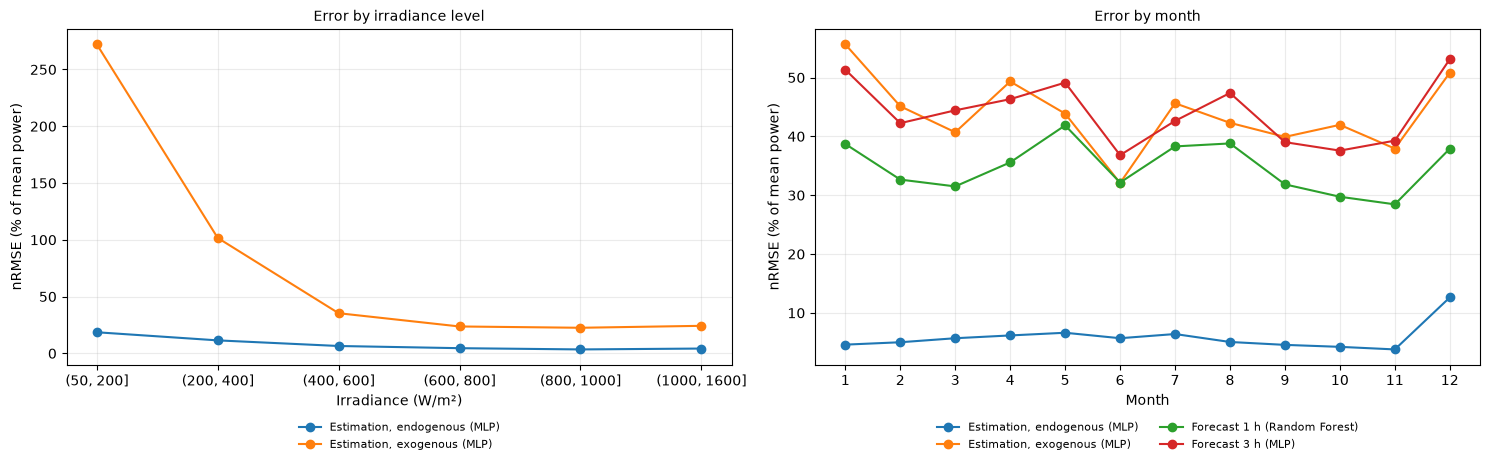

nRMSE (%) by test year; rows per year in brackets for the endogenous task:


,"2016 (192,871)","2017 (4,067)","2018 (55,230)","2023 (12,697)"
"Estimation, endogenous",5.9,7.5,5.1,6.0
"Estimation, exogenous",42.1,60.0,45.3,65.1
Forecast 1 h,32.9,129.2,31.3,41.6
Forecast 3 h,40.8,224.5,41.2,58.5


Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_eval_residuals.png


In [10]:
# Irradiance bins (W/m²) for the residual analysis.
IRRADIANCE_BINS = [50, 200, 400, 600, 800, 1000, 1600]


def nrmse(frame, column):
    return 100 * np.sqrt(((frame[column] - frame["y_true"]) ** 2).mean()) / frame["y_true"].mean()


with (MODELS_DIR / f"scaler_{config_summary.loc['endogenous', 'group_name']}.pkl").open("rb") as file:
    endo_scaler = pickle.load(file)
endo_X_test = load_features("endogenous", "X_test")
irradiance = pd.Series(endo_scaler.inverse_transform(endo_X_test)[:, 0], index=endo_X_test.index)
irradiance_bin = pd.cut(irradiance, IRRADIANCE_BINS)

RESIDUALS_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_eval_residuals.png"
fig, (irr_ax, month_ax) = plt.subplots(1, 2, figsize=(15, 4.8))
for task in ("endogenous", "exogenous"):
    pred = predictions[task]
    by_bin = pred.groupby(irradiance_bin.reindex(pred.index), observed=True).apply(nrmse, best_models[task])
    irr_ax.plot([str(b) for b in by_bin.index], by_bin, marker="o", color=TASK_COLORS[task],
                label=f"{TASKS[task]} ({best_models[task]})")
irr_ax.set_xlabel("Irradiance (W/m²)")
irr_ax.set_ylabel("nRMSE (% of mean power)")
irr_ax.set_title("Error by irradiance level", fontsize=10)
irr_ax.grid(True, alpha=0.25)
irr_ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, frameon=False)

year_rows = {}
for task in TASKS:
    pred = predictions[task]
    by_month = pred.groupby(pred.index.month).apply(nrmse, best_models[task])
    month_ax.plot(by_month.index, by_month, marker="o", color=TASK_COLORS[task],
                  label=f"{TASKS[task]} ({best_models[task]})")
    year_rows[TASKS[task]] = pred.groupby(pred.index.year).apply(nrmse, best_models[task])
month_ax.set_xticks(range(1, 13))
month_ax.set_xlabel("Month")
month_ax.set_ylabel("nRMSE (% of mean power)")
month_ax.set_title("Error by month", fontsize=10)
month_ax.grid(True, alpha=0.25)
month_ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(RESIDUALS_PLOT_PATH, dpi=160)
plt.show()

print("nRMSE (%) by test year; rows per year in brackets for the endogenous task:")
year_table = pd.DataFrame(year_rows).T
year_table.columns = [f"{year} ({(predictions['endogenous'].index.year == year).sum():,})"
                      for year in year_table.columns]
display(year_table.round(1))
print(f"Saved to: {RESIDUALS_PLOT_PATH}")

## 4.7 Feature importance

Two views per task:

- **Built-in importance** of Random Forest and XGBoost (how much each feature is used in the trees).
- **Permutation importance** of the best model on a test sample: how much the test RMSE grows when one feature is shuffled. It works for every model type and measures importance on unseen data.

model                                       Random Forest  XGBoost
task                   feature                                    
Estimation, endogenous module_temp_1__321           0.002    0.002
                       poa_irradiance__313          0.998    0.998
Estimation, exogenous  ambient_temp__320            0.110    0.068
                       doy_cos                      0.086    0.082
                       doy_sin                      0.074    0.062
                       hour_cos                     0.693    0.739
                       hour_sin                     0.037    0.048
Forecast 1 h           ambient_temp_t               0.005    0.008
                       doy_cos                      0.014    0.014
                       doy_sin                      0.003    0.008
                       hour_cos                     0.093    0.168
                       hour_sin                     0.151    0.165
                       irradiance_t                 0.672    0.558
                       irradiance_t-1h              0.007    0.013
                       irradiance_t-24h             0.002    0.007
                       power_t                      0.020    0.016
                       power_t-15min                0.010    0.012
                       power_t-1h                   0.004    0.008
                       power_t-24h                  0.002    0.006
                       power_target-24h             0.016    0.018
Forecast 3 h           ambient_temp_t               0.013    0.011
                       doy_cos                      0.037    0.020
                       doy_sin                      0.011    0.012
                       hour_cos                     0.690    0.734
                       hour_sin                     0.054    0.061
                       irradiance_t                 0.113    0.072
                       irradiance_t-1h              0.009    0.016
                       irradiance_t-24h             0.004    0.009
                       power_t                      0.011    0.008
                       power_t-15min                0.006    0.009
                       power_t-1h                   0.007    0.012
                       power_t-24h                  0.006    0.011
                       power_target-24h             0.039    0.023

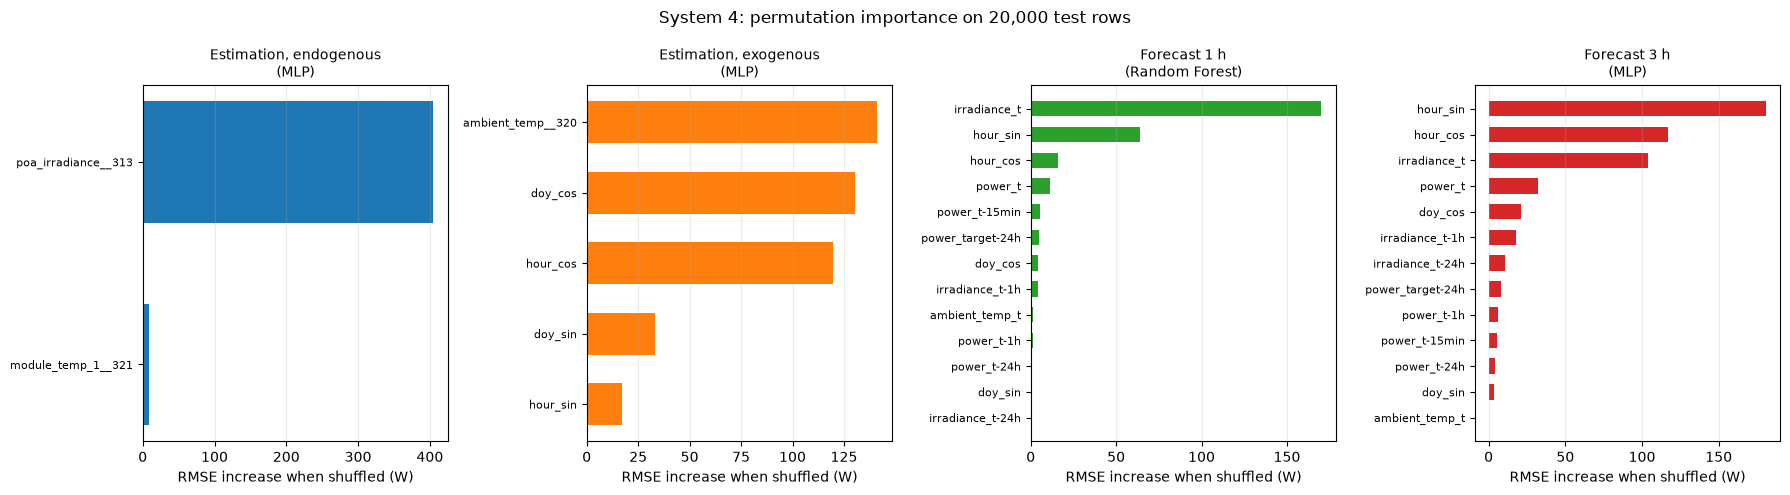

Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_eval_permutation_importance.png


In [11]:
# Permutation importance settings.
PERMUTATION_SAMPLE = 20_000
PERMUTATION_REPEATS = 5


def load_model(task, model):
    with (MODELS_DIR / f"system_{SYSTEM_ID}_{task}_{MODEL_SLUGS[model]}.pkl").open("rb") as file:
        return pickle.load(file)


builtin_rows, permutation = [], {}
for task in TASKS:
    X_test = load_features(task, "X_test")
    y_test = load_features(task, "y_test")[TARGET]
    for model in ("Random Forest", "XGBoost"):
        importances = load_model(task, model).feature_importances_
        builtin_rows += [{"task": TASKS[task], "model": model, "feature": f, "importance": v}
                         for f, v in zip(X_test.columns, importances)]
    sample = X_test.sample(n=min(PERMUTATION_SAMPLE, len(X_test)), random_state=0)
    result = permutation_importance(load_model(task, best_models[task]), sample, y_test.loc[sample.index],
                                    scoring="neg_root_mean_squared_error",
                                    n_repeats=PERMUTATION_REPEATS, random_state=0, n_jobs=-1)
    permutation[task] = pd.Series(result.importances_mean, index=X_test.columns).sort_values()

builtin = (pd.DataFrame(builtin_rows)
           .pivot_table(index=["task", "feature"], columns="model", values="importance"))
display(builtin.round(3))

IMPORTANCE_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_eval_permutation_importance.png"
fig, axes = plt.subplots(1, len(TASKS), figsize=(18, 5))
for ax, task in zip(axes, TASKS):
    values = permutation[task]
    ax.barh(values.index, values, color=TASK_COLORS[task], height=0.6)
    ax.set_title(f"{TASKS[task]}\n({best_models[task]})", fontsize=10)
    ax.set_xlabel("RMSE increase when shuffled (W)")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(True, axis="x", alpha=0.25)
fig.suptitle(f"System {SYSTEM_ID}: permutation importance on {PERMUTATION_SAMPLE:,} test rows")
fig.tight_layout()
fig.savefig(IMPORTANCE_PLOT_PATH, dpi=160)
plt.show()
print(f"Saved to: {IMPORTANCE_PLOT_PATH}")

## 4.8 Best model per task

The selection balances accuracy and efficiency, as the thesis description asks: among the models **tied with the most accurate one** (section 4.2), the one with the shortest training time is chosen; prediction time and model size are reported alongside. The best estimation model (endogenous task) is the normal-behaviour reference for the anomaly detection.

In [12]:
best_rows = []
for task in TASKS:
    tied = ties.loc[TASKS[task]].query("tied_with_best").index.tolist()
    m = metrics[task].loc[tied]
    chosen = m["fit_seconds"].idxmin()
    best_rows.append({"task": TASKS[task], "most_accurate": best_models[task], "tied_models": ", ".join(tied),
                      "chosen": chosen, "test_RMSE": m.loc[chosen, "test_RMSE"],
                      "test_R2": m.loc[chosen, "test_R2"], "fit_seconds": m.loc[chosen, "fit_seconds"],
                      "predict_seconds": m.loc[chosen, "predict_seconds"],
                      "model_size_kb": m.loc[chosen, "model_size_kb"]})

best_table = pd.DataFrame(best_rows).set_index("task")
BEST_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_eval_best_models.csv"
best_table.to_csv(BEST_PATH)
with pd.option_context("display.max_colwidth", None):
    display(best_table.round(3))
print(f"Saved to: {BEST_PATH}")

,most_accurate,tied_models,chosen,test_RMSE,test_R2,fit_seconds,predict_seconds,model_size_kb
task,,,,,,,,
"Estimation, endogenous",MLP,MLP,MLP,28.290,0.991,8.808,0.073,62.088
"Estimation, exogenous",MLP,MLP,MLP,217.159,0.478,84.029,0.095,68.560
Forecast 1 h,Random Forest,Random Forest,Random Forest,140.033,0.810,5.078,0.024,10104.886
Forecast 3 h,MLP,"Random Forest, MLP",Random Forest,180.401,0.684,4.536,0.033,10260.276


Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_eval_best_models.csv
